# Recognising hand-washing steps with a CNN

Good hand hygiene follows a fixed sequence of steps. A system that recognises which step someone is doing
could give feedback in hospitals or food preparation. This notebook trains image classifiers to tell
**eight hand-washing steps** apart from photos.

**Data:** 80 photos I took and labelled myself, 10 for each step, at 150×150 pixels.

The notebook also shows how much the way you split a small dataset changes the result, which turned out to
be the most important finding.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")
keras.utils.disable_interactive_logging()  # no download progress bars in the saved notebook

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)


def save(name):
    plt.tight_layout()
    plt.savefig(IMAGES / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

TensorFlow 2.21.0


## 1. The photos

In [2]:
files, labels, frame = [], [], []
for step in range(1, 9):
    for i, path in enumerate(sorted(Path(f"data/step_{step}").glob("*.jpg"))):
        files.append(path)
        labels.append(step - 1)
        frame.append(i)

X = np.stack([np.asarray(Image.open(f).convert("RGB"), dtype=np.float32) for f in files])
y = np.array(labels)
frame = np.array(frame)
print(X.shape, "images,", np.bincount(y), "per step")

(80, 150, 150, 3) images, [10 10 10 10 10 10 10 10] per step


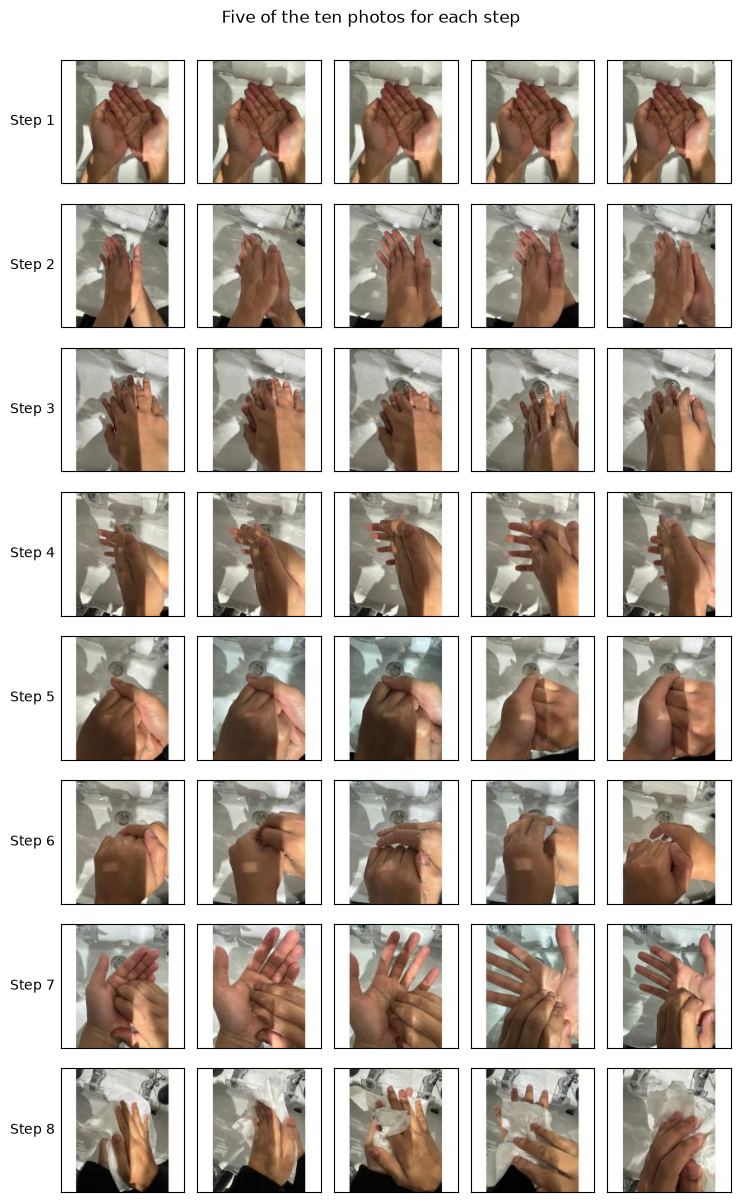

In [3]:
fig, axes = plt.subplots(8, 5, figsize=(7.5, 12))
for step in range(8):
    for j, k in enumerate([0, 2, 4, 6, 9]):
        ax = axes[step, j]
        ax.imshow(X[(y == step) & (frame == k)][0].astype("uint8"))
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"Step {step + 1}", rotation=0, ha="right", va="center")
fig.suptitle("Five of the ten photos for each step", y=1.0)
save("dataset")

Within each step, the photos were taken in one go, so they're very similar to each other: same angle,
same light, same sink. The next section measures how similar.

## 2. How similar are the photos?

To compare photos I describe each one with a pretrained image model, **MobileNetV2** trained on ImageNet,
then use the cosine similarity between those descriptions.

In [4]:
SIZE = 160
backbone = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False,
                                          weights="imagenet", pooling="avg")
backbone.trainable = False


def embed(images):
    x = tf.image.resize(images, (SIZE, SIZE))
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    return backbone.predict(x, verbose=0)


features = embed(X)
unit = features / np.linalg.norm(features, axis=1, keepdims=True)
similarity = unit @ unit.T
np.fill_diagonal(similarity, -1)

nearest = similarity.argmax(axis=1)
same_step = similarity[y[:, None] == y[None, :]]
other_step = similarity[y[:, None] != y[None, :]]
print(f"Nearest photo is from the same step for {np.mean(y[nearest] == y):.0%} of photos")
print(f"Average similarity: same step {same_step[same_step > -1].mean():.2f}, different steps {other_step.mean():.2f}")

Nearest photo is from the same step for 98% of photos
Average similarity: same step 0.79, different steps 0.63


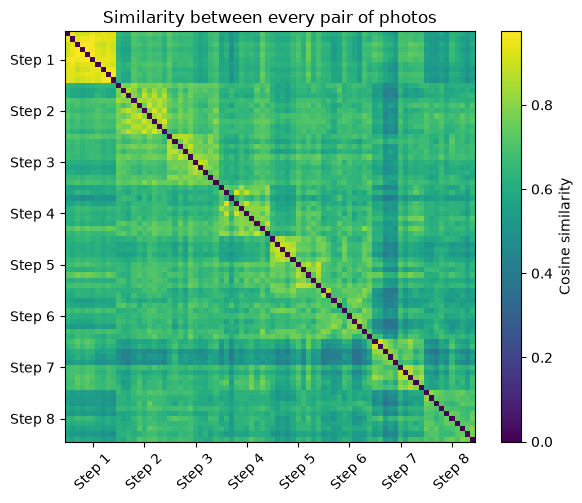

In [5]:
plt.figure(figsize=(6, 5))
plt.imshow(similarity.clip(0, 1), cmap="viridis")
ticks = np.arange(5, 80, 10)
plt.xticks(ticks, [f"Step {i}" for i in range(1, 9)], rotation=45)
plt.yticks(ticks, [f"Step {i}" for i in range(1, 9)])
plt.colorbar(label="Cosine similarity")
plt.title("Similarity between every pair of photos")
save("similarity")

The bright squares on the diagonal show that photos of the same step are much more alike than photos of
different steps. That's partly because the steps really do look different, and partly because each step was
photographed in a single burst.

This matters for testing. If the photos are split at random, every test photo has near-copies from the same
burst in the training set, so the test mostly checks whether the model can recognise **those exact shots
again**. That makes it look better than it is.

So I evaluate in two ways:

- **Random split:** 5-fold stratified cross-validation, the usual approach.
- **Held-out frames:** train on the first 7 photos of each step and test on the last 3. The test photos
  are still from the same session, but they're never the training photos' immediate neighbours. This is
  stricter, though it's still not a test on new people or new sinks.

In [6]:
def random_split_folds():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    return list(cv.split(X, y))


def held_out_frames_split():
    train = np.where(frame < 7)[0]
    test = np.where(frame >= 7)[0]
    return [(train, test)]


SPLITS = {"Random split (5-fold)": random_split_folds(), "Held-out frames": held_out_frames_split()}

## 3. Model 1: a small CNN trained from scratch

A compact convolutional network with data augmentation (small rotations, zoom, contrast changes and
horizontal flips). Flips are safe because each step is done with both hands in turn.

In [7]:
def make_cnn():
    model = keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        layers.Rescaling(1 / 255),
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.08, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
        layers.RandomContrast(0.2, seed=SEED),
        layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(8, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def evaluate_cnn(folds, epochs=60):
    scores, last = [], None
    for train, test in folds:
        tf.keras.utils.set_random_seed(SEED)
        model = make_cnn()
        model.fit(X[train], y[train], epochs=epochs, batch_size=16, verbose=0)
        pred = model.predict(X[test], verbose=0).argmax(axis=1)
        scores.append(accuracy_score(y[test], pred))
        last = (test, pred)
    return np.mean(scores), np.std(scores), last


make_cnn().summary()

In [8]:
results = []
predictions = {}
for split_name, folds in SPLITS.items():
    mean, std, last = evaluate_cnn(folds)
    results.append({"model": "CNN from scratch", "evaluation": split_name, "accuracy": mean, "std": std})
    predictions[("CNN from scratch", split_name)] = last
    print(f"{split_name}: {mean:.1%}" + (f" ± {std:.1%}" if len(folds) > 1 else ""))

Random split (5-fold): 65.0% ± 18.4%


Held-out frames: 29.2%


## 4. Model 2: transfer learning with MobileNetV2

Instead of learning visual features from 70 photos, reuse the features MobileNetV2 already learned from
over a million ImageNet images, and train only a simple classifier (logistic regression) on top. With so
little data this is usually the better approach.

In [9]:
def evaluate_transfer(folds):
    scores, last = [], None
    for train, test in folds:
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
        clf.fit(features[train], y[train])
        pred = clf.predict(features[test])
        scores.append(accuracy_score(y[test], pred))
        last = (test, pred)
    return np.mean(scores), np.std(scores), last


for split_name, folds in SPLITS.items():
    mean, std, last = evaluate_transfer(folds)
    results.append({"model": "MobileNetV2 + logistic regression", "evaluation": split_name, "accuracy": mean, "std": std})
    predictions[("MobileNetV2 + logistic regression", split_name)] = last
    print(f"{split_name}: {mean:.1%}" + (f" ± {std:.1%}" if len(folds) > 1 else ""))

Random split (5-fold): 96.2% ± 3.1%
Held-out frames: 95.8%


## 5. Results

In [10]:
table = pd.DataFrame(results).pivot(index="model", columns="evaluation", values="accuracy")
table = table[["Random split (5-fold)", "Held-out frames"]]
print(f"Guessing at random would score {1 / 8:.1%}.")
table.style.format("{:.1%}")

Guessing at random would score 12.5%.


evaluation,Random split (5-fold),Held-out frames
model,,
CNN from scratch,65.0%,29.2%
MobileNetV2 + logistic regression,96.2%,95.8%


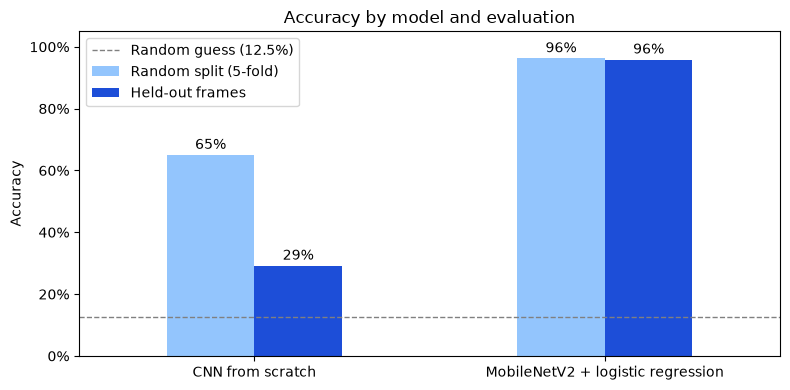

In [11]:
ax = table.plot.bar(figsize=(8, 4), rot=0, color=["#93c5fd", "#1d4ed8"])
ax.axhline(1 / 8, color="grey", ls="--", lw=1, label="Random guess (12.5%)")
ax.set(ylabel="Accuracy", ylim=(0, 1.05), xlabel="", title="Accuracy by model and evaluation")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], padding=2)
ax.legend(loc="upper left")
save("results")

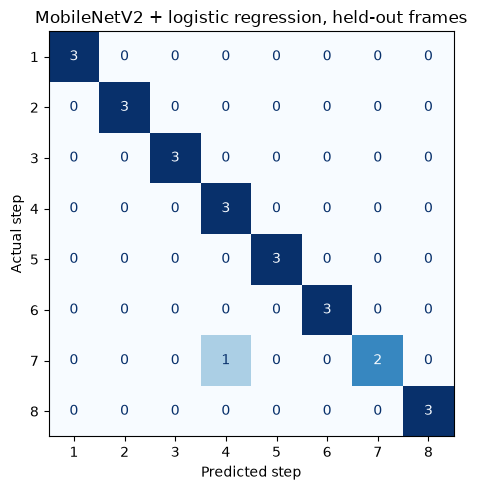

In [12]:
best = table["Held-out frames"].idxmax()
test, pred = predictions[(best, "Held-out frames")]
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y[test], pred, display_labels=[f"{i}" for i in range(1, 9)],
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set(xlabel="Predicted step", ylabel="Actual step", title=f"{best}, held-out frames")
save("confusion_matrix")

1 of 24 held-out photos misclassified


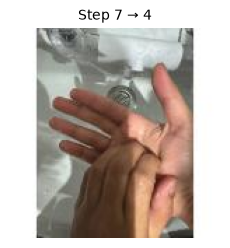

In [13]:
wrong = [(i, p) for i, p in zip(test, pred) if y[i] != p]
print(f"{len(wrong)} of {len(test)} held-out photos misclassified")
if wrong:
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.4 * len(wrong), 2.8), squeeze=False)
    for ax, (i, p) in zip(axes[0], wrong):
        ax.imshow(X[i].astype("uint8"))
        ax.set_title(f"Step {y[i] + 1} → {p + 1}", fontsize=10)
        ax.axis("off")
    save("mistakes")

## 6. What this does and doesn't show

- **The CNN trained from scratch mostly memorised the shots.** It looks passable on the random split, where
  test photos have near-copies in the training set, but falls sharply on held-out frames. 70 photos aren't
  enough to learn useful visual features from nothing.
- **Transfer learning holds up.** Reusing MobileNetV2's features gives high accuracy on both evaluations,
  so it is picking up on what the hand positions look like rather than recognising individual shots. It's
  also far faster: the features are computed once and the classifier trains in under a second.
- **None of these numbers say how well it would work for other people.** Every photo shows the same
  hands, at the same sink, in the same light, taken in one session. A real system would need photos from
  many people and places, with testing on people it has never seen.

**Next steps:** collect data from more people and settings and split by person; use short video clips
rather than single frames, since hand-washing is a motion; and fine-tune the top layers of the pretrained
network once there's enough data.